# 2025년 서울 고령 보행자 교통사고 분석

**핵심 취재 질문:** 동대문구는 왜 고령 보행자 사고가 가장 많이 발생한 지역인가?

2025년 서울 25개 자치구의 사고 건수, 고령인구 대비 발생 수준, 전체 보행자 사고 중 고령 보행자 사고 비중을 차례로 비교한다. 수치로 확인된 사실과 아직 검증되지 않은 원인을 구분한다.

- 출처: 한국도로교통공단 TAAS(2025년 보행자·고령 보행자 사고), 서울 열린데이터광장(2025년 4분기 고령인구)
- 분석 도구: Python, pandas, Google Colab
- **해석 유의:** 거주 고령인구와 사고 발생 장소의 인구가 다르고, 실제 보행량도 알 수 없으므로 개인의 사고 위험률을 뜻하지 않는다.

## 1. 자료 불러오기

Colab에서 실행한다. `data/` 폴더의 세 파일을 아래 이름으로 준비해 한꺼번에 업로드한다. Colab 실행 환경은 로컬 VS Code 폴더와 자동으로 연결되지 않는다.

- `2025_고령보행자_사고.xlsx`
- `2025_고령인구.csv`
- `2025_전체보행자사고.xlsx`

In [ ]:
import pandas as pd
from google.colab import files

uploaded = files.upload()  # 세 파일을 선택

accident = pd.read_excel('2025_고령보행자사고.xlsx')
all_pedestrian = pd.read_excel('2025_전체보행자사고.xlsx')

# 이 CSV는 위쪽 4행이 여러 단계의 열 제목이므로 열 이름 없이 읽는다.
population_raw = pd.read_csv('2025_고령인구.csv', skiprows=4, header=None)

print('고령 보행자 사고 원본:', accident.shape)
print('전체 보행자 사고 원본:', all_pedestrian.shape)
print('고령인구 원본:', population_raw.shape)

Saving 2025_고령보행자사고.xlsx to 2025_고령보행자사고 (2).xlsx
Saving 2025_고령인구.csv to 2025_고령인구 (2).csv
Saving 2025_전체보행자사고.xlsx to 2025_전체보행자사고 (2).xlsx
고령 보행자 사고 원본: (740, 4)
전체 보행자 사고 원본: (739, 4)
고령인구 원본: (26, 14)


/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


## 2. 전처리 — 서울 25개 자치구만 추출

`시도` 앞뒤의 공백을 제거하고 `사고[건]`만 선택한다. 인구 CSV에서는 두 번째 열(자치구), 여섯 번째 열(65세 이상 인구 소계)을 사용한다.

In [ ]:
def seoul_accident_counts(df, new_column):
    data = df.copy()
    data['시도'] = data['시도'].str.strip()
    data = data.loc[
        (data['시도'] == '서울') &
        (data['연도'] == '사고[건]') &
        (data['시군구'] != '합계'),
        ['시군구', '2025']
    ].copy()
    return data.rename(columns={'2025': new_column})

seoul_accident = seoul_accident_counts(accident, '사고건수')
seoul_all = seoul_accident_counts(all_pedestrian, '전체보행자사고')

population = population_raw.iloc[:, [1, 5]].copy()
population.columns = ['시군구', '고령인구']
population = population[population['시군구'] != '소계'].copy()
population['고령인구'] = pd.to_numeric(population['고령인구'])

print('고령 보행자 사고 지역 수:', len(seoul_accident))
print('전체 보행자 사고 지역 수:', len(seoul_all))
print('고령인구 지역 수:', len(population))
print('고령 보행자 사고 합계:', seoul_accident['사고건수'].sum())
print('전체 보행자 사고 합계:', seoul_all['전체보행자사고'].sum())

display(population.head())

고령 보행자 사고 지역 수: 25
전체 보행자 사고 지역 수: 25
고령인구 지역 수: 25
고령 보행자 사고 합계: 2060.0
전체 보행자 사고 합계: 7511.0


,시군구,고령인구
1,종로구,30958
2,중구,27623
3,용산구,40470
4,성동구,53444
5,광진구,62783


## 3. 분석 1 — 고령인구 대비 사고 건수

**질문:** 거주 고령인구 규모를 고려해도 동대문구의 사고 발생 수준이 높은가?

**계산:** 고령인구 1만 명당 사고 건수 = 고령 보행자 사고 건수 ÷ 해당 자치구의 65세 이상 인구 × 10,000.

In [ ]:
merged = pd.merge(seoul_accident, population, on='시군구', how='inner', validate='one_to_one')
assert len(merged) == 25, '결합 후 지역 수가 25개인지 확인하세요.'

merged['1만명당_사고건수'] = merged['사고건수'] / merged['고령인구'] * 10000
merged['건수순위'] = merged['사고건수'].rank(ascending=False, method='min').astype(int)
merged['인구대비순위'] = merged['1만명당_사고건수'].rank(ascending=False, method='min').astype(int)

result = merged.sort_values('1만명당_사고건수', ascending=False)
display(result.round({'1만명당_사고건수': 2}))

,시군구,사고건수,고령인구,1만명당_사고건수,건수순위,인구대비순위
1,중구,61.0,27623,22.08,18,1
4,동대문구,132.0,72779,18.14,1,2
0,종로구,51.0,30958,16.47,21,3
24,금천구,83.0,50658,16.38,14,4
12,영등포구,106.0,73471,14.43,6,5
23,강북구,105.0,74406,14.11,7,6
20,중랑구,105.0,88128,11.91,7,7
15,강남구,113.0,95530,11.83,3,8
16,강동구,113.0,98148,11.51,3,9
7,은평구,117.0,102485,11.42,2,10


### 분석 1에서 확인한 사실

- **동대문구:** 고령 보행자 사고 132건(서울 **1위**). 2025년 4분기 65세 이상 인구 72,779명 기준 **1만 명당 18.14건(2위)**.
- **중구:** 사고 61건(건수 18위), 고령인구 1만 명당 22.08건(1위).
- 동대문구의 사고 건수 1위는 단지 거주 고령인구가 많기 때문이라고 보기 어렵다. 다만 이 지표만으로 원인을 판단할 수 없다.

## 4. 분석 2 — 전체 보행자 사고 중 고령 보행자 사고 비중

**질문:** 동대문구에서 일어난 보행자 사고 가운데 고령 보행자 사고의 비중도 높은가?

**계산:** 고령 보행자 사고 비중(%) = 고령 보행자 사고 건수 ÷ 전체 보행자 사고 건수 × 100.

두 TAAS 통계가 모두 2025년 같은 지역에서 발생한 보행자 피해 사고를 집계한 자료라는 전제로 비교한다.

In [ ]:
comparison = pd.merge(merged, seoul_all, on='시군구', how='inner', validate='one_to_one')
assert len(comparison) == 25, '결합 후 지역 수가 25개인지 확인하세요.'
assert (comparison['사고건수'] <= comparison['전체보행자사고']).all()

comparison['고령사고비중'] = comparison['사고건수'] / comparison['전체보행자사고'] * 100
comparison['비중순위'] = comparison['고령사고비중'].rank(ascending=False, method='min').astype(int)
comparison_sorted = comparison.sort_values('고령사고비중', ascending=False)

display(comparison_sorted[
    ['시군구', '전체보행자사고', '사고건수', '고령사고비중', '비중순위']
].round({'고령사고비중': 2}))

seoul_share = seoul_accident['사고건수'].sum() / seoul_all['전체보행자사고'].sum() * 100
print(f'서울 전체 고령 보행자 사고 비중: {seoul_share:.2f}%')

,시군구,전체보행자사고,사고건수,고령사고비중,비중순위
23,강북구,250.0,105.0,42.00,1
7,은평구,311.0,117.0,37.62,2
4,동대문구,356.0,132.0,37.08,3
24,금천구,231.0,83.0,35.93,4
8,서대문구,206.0,71.0,34.47,5
21,노원구,256.0,85.0,33.20,6
20,중랑구,318.0,105.0,33.02,7
16,강동구,345.0,113.0,32.75,8
5,성북구,271.0,88.0,32.47,9
19,양천구,292.0,93.0,31.85,10


서울 전체 고령 보행자 사고 비중: 27.43%


### 분석 2에서 확인한 사실

- **동대문구:** 전체 보행자 사고 356건 중 고령 보행자 사고 132건, **37.08%(서울 3위)**.
- 서울 전체: 7,511건 중 2,060건, **27.43%**. 동대문구는 서울 전체보다 **약 9.65%p 높다**.
- **강북구 42.00%(1위)**, **은평구 37.62%(2위)**, 동대문구 37.08%(3위).
- 동대문구는 고령 보행자 사고 **건수 1위·고령인구 대비 2위·전체 사고 중 비중 3위**다.

**해석의 한계:** 고령사고 비중은 고령자 보행량뿐 아니라 다른 연령대의 사고 건수에도 좌우된다. 높은 비중을 곧바로 고령 보행자 개인의 더 높은 사고 위험으로 해석하지 않는다.

## 5. 앞으로 확인할 취재 질문

1. 동대문구의 고령 보행자 사고는 특정 교차로·도로·생활권에 집중되는가? **사고 위치 자료 확보 후 분석**.
2. 확인된 사고 집중 지점의 보행환경과 안전시설, 노인보호구역 지정·관리 상태는 어떠한가? **현장 취재 필요**.
3. 고령 보행자와 다른 연령대의 이동·보행량 차이가 지역별 지표에 어떤 영향을 주는가? **현재 자료로 판단 불가**.

분석에서 발견한 패턴은 취재를 시작할 근거이지, 사고 원인을 증명하는 결과가 아니다.

In [ ]:

from google.colab import files

files.upload()


# 동대문구 개별 사고 데이터 불러오기
detail = pd.read_excel(
    "2025_동대문구_고령보행자사고상세.xlsx"
)

# 데이터 크기와 열 이름 확인
print("데이터 크기:", detail.shape)
print("열 이름:", detail.columns.tolist())

display(detail.head())



Saving 2025_동대문구_고령보행자사고상세.xlsx to 2025_동대문구_고령보행자사고상세 (1).xlsx
데이터 크기: (132, 22)
열 이름: ['구분번호', '발생년월', '주야', '시군구', '사고내용', '사망자수', '중상자수', '경상자수', '부상신고자수', '사고유형', '법규위반', '노면상태', '기상상태', '도로형태', '가해운전자 차종', '가해운전자 성별', '가해운전자 연령대', '가해운전자 상해정도', '피해운전자 차종', '피해운전자 성별', '피해운전자 연령대', '피해운전자 상해정도']


,구분번호,발생년월,주야,시군구,사고내용,사망자수,중상자수,경상자수,부상신고자수,사고유형,...,기상상태,도로형태,가해운전자 차종,가해운전자 성별,가해운전자 연령대,가해운전자 상해정도,피해운전자 차종,피해운전자 성별,피해운전자 연령대,피해운전자 상해정도
0,2025000802,2025년 1월,주간,서울특별시 동대문구,경상사고,0,0,1,0,차대사람 - 횡단중,...,맑음,교차로 - 교차로횡단보도내,이륜,남,65세 이상,상해없음,보행자,여,65세 이상,경상
1,2025000894,2025년 1월,주간,서울특별시 동대문구,경상사고,0,0,1,0,차대사람 - 횡단중,...,맑음,교차로 - 교차로횡단보도내,승용,여,50-59세,상해없음,보행자,여,65세 이상,경상
2,2025003013,2025년 1월,주간,서울특별시 동대문구,경상사고,0,0,1,0,차대사람 - 횡단중,...,맑음,교차로 - 교차로횡단보도내,원동기,남,65세 이상,상해없음,보행자,여,65세 이상,경상
3,2025003382,2025년 1월,야간,서울특별시 동대문구,경상사고,0,0,1,0,차대사람 - 기타,...,맑음,단일로 - 기타,승용,남,40-49세,상해없음,보행자,여,65세 이상,경상
4,2025003880,2025년 1월,주간,서울특별시 동대문구,중상사고,0,1,0,0,차대사람 - 기타,...,맑음,단일로 - 기타,승용,여,65세 이상,상해없음,보행자,여,65세 이상,중상


In [ ]:

# 사고유형별 발생 건수
accident_types = detail['사고유형'].value_counts()

# 전체 사고 중 비율(%)
accident_type_ratio = (
    detail['사고유형'].value_counts(normalize=True) * 100
).round(2)

# 건수와 비율을 하나의 표로 정리
type_result = pd.DataFrame({
    '사고건수': accident_types,
    '비율(%)': accident_type_ratio
})

display(type_result)

print("전체 사고 건수:", type_result['사고건수'].sum())


,사고건수,비율(%)
사고유형,,
차대사람 - 기타,61,46.21
차대사람 - 횡단중,40,30.30
차대사람 - 보도통행중,14,10.61
차대사람 - 차도통행중,9,6.82
차대사람 - 길가장자리구역통행중,6,4.55
차대차 - 충돌,1,0.76
차대차 - 기타,1,0.76


전체 사고 건수: 132


In [ ]:

# 사고유형과 도로형태를 교차해서 건수 계산
road_type = pd.crosstab(
    detail['사고유형'],
    detail['도로형태']
)

display(road_type)

print("전체 사고 건수:", road_type.to_numpy().sum())


도로형태,교차로 - 교차로부근,교차로 - 교차로안,교차로 - 교차로횡단보도내,기타 - 기타,단일로 - 기타
사고유형,,,,,
차대사람 - 기타,8,2,0,22,29
차대사람 - 길가장자리구역통행중,0,0,0,1,5
차대사람 - 보도통행중,0,0,1,6,7
차대사람 - 차도통행중,1,2,0,1,5
차대사람 - 횡단중,1,7,17,4,11
차대차 - 기타,0,0,0,1,0
차대차 - 충돌,1,0,0,0,0


전체 사고 건수: 132


In [ ]:

# 교차로 횡단보도 내 사고만 추출
crosswalk = detail[
    detail['도로형태'] == '교차로 - 교차로횡단보도내'
]

# 법규 위반별 사고 건수
crosswalk_violations = crosswalk['법규위반'].value_counts()

print("교차로 횡단보도 내 사고:", len(crosswalk))
display(crosswalk_violations)


교차로 횡단보도 내 사고: 18


,count
법규위반,
안전운전불이행,8
보행자보호의무위반,6
신호위반,4


In [ ]:

from google.colab import files

files.upload()

# 사고다발지역 데이터 불러오기
hotspots = pd.read_excel(
    "2025_서울_고령보행자사고다발지역.xlsx"
)

# 동대문구 다발지역만 추출
dongdaemun_hotspots = hotspots[
    hotspots['시도'].str.contains('동대문구')
].copy()

# 제기동 여부 구분
dongdaemun_hotspots['제기동여부'] = (
    dongdaemun_hotspots['장소설명'].str.contains('제기동')
)

print("동대문구 다발지역:", len(dongdaemun_hotspots))
print("제기동 다발지역:", dongdaemun_hotspots['제기동여부'].sum())

display(dongdaemun_hotspots)


Saving 2025_서울_고령보행자사고다발지역.xlsx to 2025_서울_고령보행자사고다발지역.xlsx
동대문구 다발지역: 10
제기동 다발지역: 5


,시도,장소설명,사고건수,사상자수,사망자수,중상자수,경상자수,부상신고자수,제기동여부
7,서울 동대문구1,서울 동대문구 제기동(동서시장 부근),12,12,0,12,0,0,True
8,서울 동대문구2,서울 동대문구 제기동(청량리전통시장 부근),10,10,0,10,0,0,True
9,서울 동대문구3,서울 동대문구 제기동(경동시장교차로 부근),6,6,2,4,0,0,True
10,서울 동대문구4,서울 동대문구 제기동(경동시장광성상가 부근),6,6,0,6,0,0,True
11,서울 동대문구5,서울 동대문구 장안동(장한평역교차로 부근),5,5,2,3,0,0,False
12,서울 동대문구6,서울 동대문구 신설동(양가네분식 부근),5,5,1,4,0,0,False
13,서울 동대문구7,서울 동대문구 청량리동(떡전교사거리 부근),5,5,1,4,0,0,False
14,서울 동대문구8,서울 동대문구 전농동(새성수약국 부근),5,5,0,5,0,0,False
15,서울 동대문구9,서울 동대문구 제기동(홍파초교교차로 부근),5,5,0,5,0,0,True
16,서울 동대문구10,서울 동대문구 회기동(회기역앞교차로 부근),5,5,0,5,0,0,False


In [ ]:

# 장소설명에서 동 이름 추출
dongdaemun_hotspots['동'] = (
    dongdaemun_hotspots['장소설명']
    .str.extract(r'동대문구\s+([^\s(]+동)')
)

# 동별 사고다발지역 개수
dong_counts = (
    dongdaemun_hotspots['동']
    .value_counts()
)

display(dong_counts)


,count
동,
제기동,5
장안동,1
신설동,1
청량리동,1
전농동,1
회기동,1


Selecting previously unselected package fonts-nanum.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../fonts-nanum_20200506-1_all.deb ...
Unpacking fonts-nanum (20200506-1) ...
Setting up fonts-nanum (20200506-1) ...
Processing triggers for fontconfig (2.15.0-1.1ubuntu2) ...


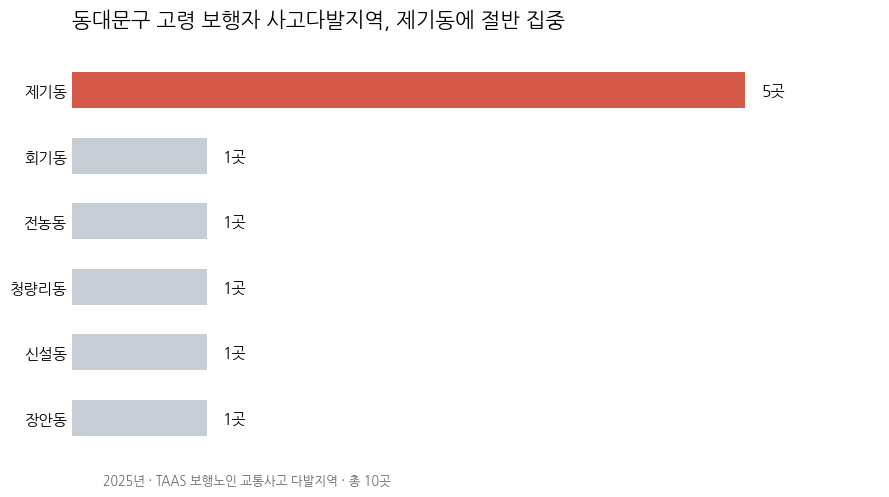

In [ ]:

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 1. Colab에 한글 폰트 설치
!apt-get -qq install fonts-nanum

# 2. 설치한 폰트를 Matplotlib에 등록
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fm.fontManager.addfont(font_path)
font_name = fm.FontProperties(fname=font_path).get_name()

plt.rcParams['font.family'] = font_name
plt.rcParams['axes.unicode_minus'] = False

# 3. 그래프 데이터 정렬
graph_data = dong_counts.sort_values()

# 4. 그래프 생성
fig, ax = plt.subplots(figsize=(9, 5))

colors = [
    '#D65A4A' if dong == '제기동' else '#C7CDD4'
    for dong in graph_data.index
]

bars = ax.barh(
    graph_data.index,
    graph_data.values,
    color=colors,
    height=0.55
)

# 5. 막대 끝에 숫자 표시
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.12,
        bar.get_y() + bar.get_height() / 2,
        f'{int(width)}곳',
        va='center',
        fontsize=11
    )

# 6. 디자인 정리
ax.set_xlim(0, 6)
ax.set_xticks([])
ax.set_ylabel('')
ax.set_title(
    '동대문구 고령 보행자 사고다발지역, 제기동에 절반 집중',
    fontsize=15,
    fontweight='bold',
    loc='left',
    pad=20
)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(axis='y', length=0, labelsize=11)

fig.text(
    0.12, 0.02,
    '2025년 · TAAS 보행노인 교통사고 다발지역 · 총 10곳',
    fontsize=9,
    color='#666666'
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


## 분석 3. 동대문구 고령 보행자 사고의 유형과 집중 지역

### 분석 질문

동대문구의 고령 보행자 사고는 어떤 상황에서 발생하며, 사고다발지역은 어디에 분포하는가?

### 분석 방법

TAAS의 2025년 동대문구 고령 보행자 사고 상세자료 132건과 서울시 보행노인 교통사고 다발지역 자료를 분석했다.

- `value_counts()`로 사고유형별 발생 건수를 계산했다.
- `pd.crosstab()`으로 사고유형과 도로형태를 비교했다.
- 교차로 횡단보도 내 사고의 법규 위반 유형을 확인했다.
- 사고다발지역의 장소 설명에서 동 이름을 추출하고 동별 분포를 비교했다.

### 주요 발견

**1. 사고유형 가운데 '차대사람 - 기타'가 가장 많았다.**

동대문구 고령 보행자 사고 132건 중 `차대사람 - 기타`가 61건(46.21%)으로 가장 많았다. `차대사람 - 횡단중`은 40건(30.30%)이었다.

**2. 교차로 횡단보도 내 사고는 18건이었다.**

18건에 기록된 법규 위반은 안전운전불이행 8건, 보행자보호의무위반 6건, 신호위반 4건이었다.

다만 법규 위반 기록만으로 사고의 구체적인 발생 원인이나 시설 문제를 단정할 수 없다.

**3. 동대문구 사고다발지역 10곳 중 5곳이 제기동에 위치했다.**

제기동에는 동서시장 부근(12건), 청량리전통시장 부근(10건), 경동시장교차로 부근(6건), 경동시장광성상가 부근(6건), 홍파초교교차로 부근(5건)이 포함됐다.

특히 전통시장 주변에 여러 사고다발지역이 분포한다는 사실을 확인했다.

### 해석과 한계

- 사고다발지역은 일정한 선정 기준에 따라 표시된 지역으로, 동대문구 전체 사고 132건의 위치를 빠짐없이 나타내지는 않는다.
- 서로 다른 다발지역의 집계 범위가 겹칠 가능성이 있어 사고 건수를 단순 합산하지 않는다.
- 사고다발지역이 제기동에 많다는 사실만으로 제기동 거주 고령자의 사고 위험이 가장 높다고 결론 내릴 수 없다.
- 다발지역의 구체적인 보행환경과 사고 원인은 현장 취재를 통해 확인해야 한다.

### 후속 취재 질문

**제기동 시장 일대에 고령 보행자 사고다발지역이 여러 곳 나타나는 이유는 무엇인가?**

시장 주변의 보행자·차량 동선, 횡단보도와 보행신호, 노인보호구역 지정 현황 등을 현장에서 조사할 필요가 있다.

In [ ]:

# 기존 분석에서 만든 데이터 재사용
correlation_data = merged[['시군구', '고령인구', '사고건수']].copy()

print("자치구 수:", len(correlation_data))
display(correlation_data.head())

# 피어슨 상관계수 계산
r = correlation_data['고령인구'].corr(
    correlation_data['사고건수']
)

print("상관계수 r:", round(r, 3))


자치구 수: 25


,시군구,고령인구,사고건수
0,종로구,30958,51.0
1,중구,27623,61.0
2,용산구,40470,39.0
3,성동구,53444,49.0
4,동대문구,72779,132.0


상관계수 r: 0.641


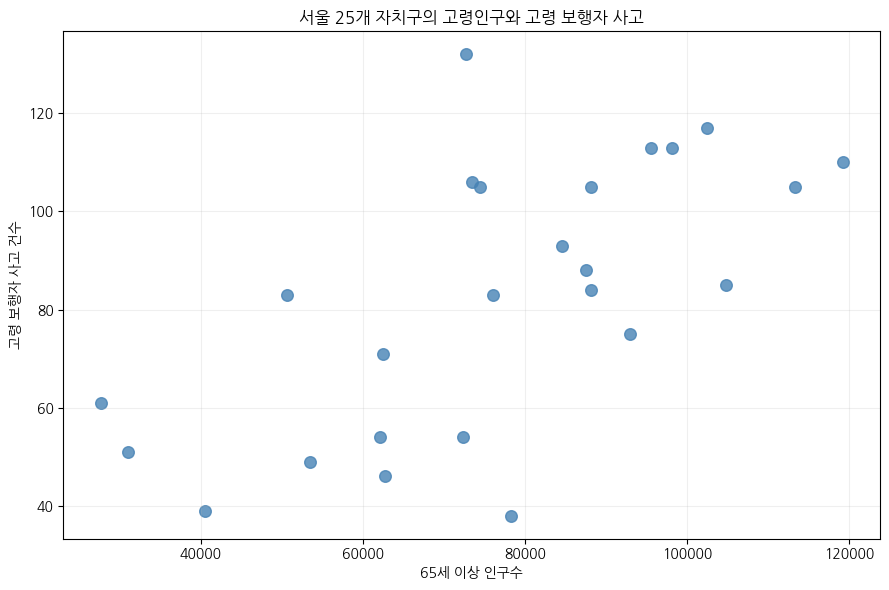

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    correlation_data['고령인구'],
    correlation_data['사고건수'],
    color='steelblue',
    s=70,
    alpha=0.8
)

plt.xlabel('65세 이상 인구수')
plt.ylabel('고령 보행자 사고 건수')
plt.title('서울 25개 자치구의 고령인구와 고령 보행자 사고')

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [ ]:

from scipy.stats import linregress

# 고령인구(X)와 사고건수(Y)
x = correlation_data['고령인구']
y = correlation_data['사고건수']

# 단순 선형회귀분석
regression = linregress(x, y)

print("기울기:", round(regression.slope, 6))
print("절편:", round(regression.intercept, 2))
print("결정계수 R²:", round(regression.rvalue ** 2, 3))


기울기: 0.000733
절편: 26.29
결정계수 R²: 0.411


In [ ]:

# 회귀선으로 계산한 사고 건수
correlation_data['예측사고건수'] = (
    regression.slope * correlation_data['고령인구']
    + regression.intercept
)

# 실제 사고 건수와 예측값의 차이
correlation_data['잔차'] = (
    correlation_data['사고건수']
    - correlation_data['예측사고건수']
)

# 잔차가 큰 순서로 정렬
residual_result = correlation_data.sort_values(
    '잔차',
    ascending=False
)

# 보기 편하게 소수점 둘째 자리까지 표시
display(
    residual_result[
        ['시군구', '고령인구', '사고건수',
         '예측사고건수', '잔차']
    ].round(2)
)


,시군구,고령인구,사고건수,예측사고건수,잔차
4,동대문구,72779,132.0,79.66,52.34
12,영등포구,73471,106.0,80.17,25.83
23,강북구,74406,105.0,80.86,24.14
24,금천구,50658,83.0,63.44,19.56
15,강남구,95530,113.0,96.35,16.65
7,은평구,102485,117.0,101.45,15.55
16,강동구,98148,113.0,98.27,14.73
1,중구,27623,61.0,46.55,14.45
20,중랑구,88128,105.0,90.92,14.08
19,양천구,84581,93.0,88.32,4.68


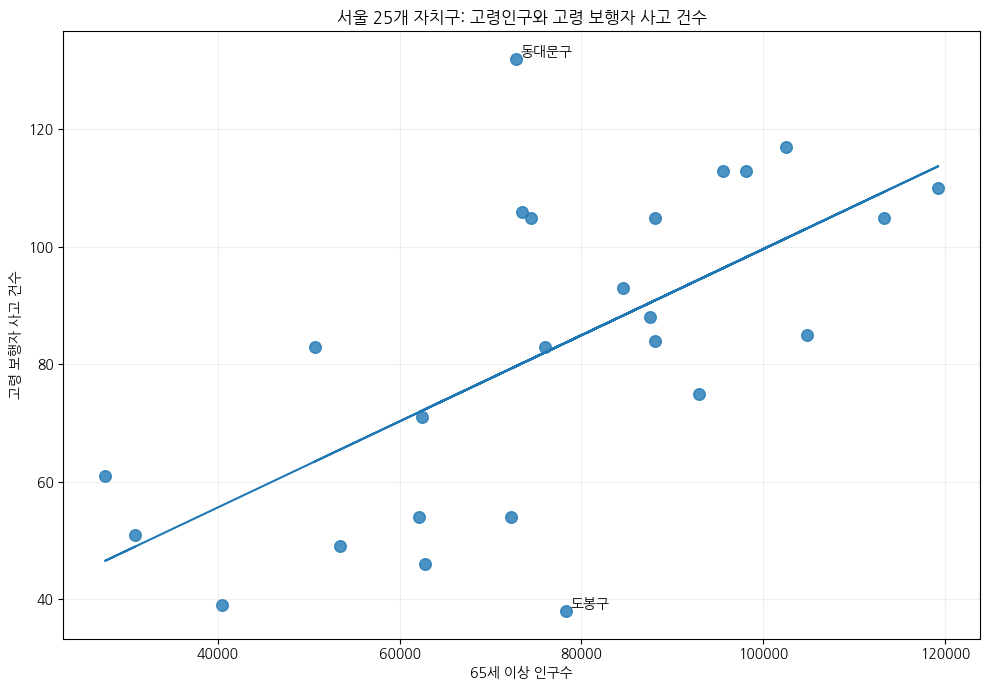

In [ ]:
plt.figure(figsize=(10, 7))

# 산점도
plt.scatter(
    correlation_data['고령인구'],
    correlation_data['사고건수'],
    s=70,
    alpha=0.8
)

# 회귀선
x_line = correlation_data['고령인구']
y_line = regression.slope * x_line + regression.intercept
plt.plot(x_line, y_line)

# 잔차가 큰 지역 이름 표시
label_districts = ['동대문구', '도봉구']

for _, row in correlation_data.iterrows():
    if row['시군구'] in label_districts:
        plt.text(
            row['고령인구'] + 500,
            row['사고건수'] + 0.5,
            row['시군구'],
            fontsize=10
        )

plt.xlabel('65세 이상 인구수')
plt.ylabel('고령 보행자 사고 건수')
plt.title('서울 25개 자치구: 고령인구와 고령 보행자 사고 건수')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 분석 4. 주요 발견 및 해석

#### 1. 고령인구와 사고 건수 사이에는 양의 상관관계가 나타났다.

2025년 서울 25개 자치구의 65세 이상 인구와 고령 보행자 사고 건수를 분석한 결과, 피어슨 상관계수는 **r = 0.641**이었다.

단순 선형회귀분석의 결정계수는 **R² = 0.411**로, 고령인구 규모를 이용한 회귀선이 자치구별 사고 건수 변동의 약 41.1%를 설명했다.

#### 2. 동대문구와 도봉구가 일반적인 경향에서 가장 크게 벗어났다.

| 구분 | 동대문구 | 도봉구 |
|---|---:|---:|
| 65세 이상 인구 | 72,779명 | 78,335명 |
| 실제 사고 건수 | 132건 | 38건 |
| 회귀선 예측값 | 79.66건 | 83.74건 |
| 잔차 | +52.34건 | -45.74건 |

동대문구는 회귀선보다 사고가 가장 많이 발생한 지역이었고, 도봉구는 가장 적게 발생한 지역이었다.

두 지역의 고령인구 규모는 비슷하지만, 실제 사고 건수는 약 3.47배 차이가 났다.

#### 3. 새로운 취재 질문

**고령인구 규모가 비슷한 동대문구와 도봉구에서 고령 보행자 사고 건수가 크게 다른 이유는 무엇인가?**

도봉구에서 사고가 적게 발생하는 배경을 탐색하되, 특정 교통안전 정책의 효과를 미리 전제하지 않는다.

#### 4. 분석의 한계

- 분석 대상이 서울 25개 자치구, 2025년 한 해에 한정된다.
- 고령인구는 거주인구 기준이며 실제 보행량이나 유동인구는 반영되지 않았다.
- 회귀선의 예측값은 통계적 비교 기준이지 정상적인 사고 건수나 정책 목표가 아니다.
- 상관관계와 잔차만으로 사고 발생 원인이나 정책 효과를 입증할 수 없다.
- 두 지역의 차이가 지속적인 현상인지는 추가 확인이 필요하다.

#### 종합 판단

이번 분석에서 동대문구와 도봉구는 서로 반대 방향으로 크게 벗어나는 지역으로 확인됐다.

따라서 특정 지역의 사고다발지점을 반복해서 조사하기보다, **두 지역의 사고 발생 수준이 크게 다른 이유를 비교하는 취재 방향**이 새로운 데이터 저널리즘 기획으로 발전할 가능성이 있다.

In [ ]:


from google.colab import files

# 도봉구 사고 상세자료 업로드
files.upload()

# 도봉구 데이터 읽기
dobong = pd.read_excel(
    "2025_도봉구_고령보행자사고상세.xlsx"
)

# 사고 건수와 열 이름 확인
print("도봉구 데이터 크기:", dobong.shape)
print("열 이름:", dobong.columns.tolist())

display(dobong.head())



Saving 2025_도봉구_고령보행자사고상세.xlsx to 2025_도봉구_고령보행자사고상세.xlsx
도봉구 데이터 크기: (38, 22)
열 이름: ['구분번호', '발생년월', '주야', '시군구', '사고내용', '사망자수', '중상자수', '경상자수', '부상신고자수', '사고유형', '법규위반', '노면상태', '기상상태', '도로형태', '가해운전자 차종', '가해운전자 성별', '가해운전자 연령대', '가해운전자 상해정도', '피해운전자 차종', '피해운전자 성별', '피해운전자 연령대', '피해운전자 상해정도']


,구분번호,발생년월,주야,시군구,사고내용,사망자수,중상자수,경상자수,부상신고자수,사고유형,...,기상상태,도로형태,가해운전자 차종,가해운전자 성별,가해운전자 연령대,가해운전자 상해정도,피해운전자 차종,피해운전자 성별,피해운전자 연령대,피해운전자 상해정도
0,2025009929,2025년 1월,주간,서울특별시 도봉구,경상사고,0,0,1,0,차대사람 - 기타,...,맑음,교차로 - 교차로안,승용,여,50-59세,기타불명,보행자,여,65세 이상,경상
1,2025016316,2025년 2월,주간,서울특별시 도봉구,중상사고,0,1,0,0,차대사람 - 길가장자리구역통행중,...,맑음,교차로 - 교차로안,화물,남,50-59세,상해없음,보행자,남,65세 이상,중상
2,2025018447,2025년 2월,주간,서울특별시 도봉구,경상사고,0,0,1,0,차대사람 - 차도통행중,...,맑음,교차로 - 교차로부근,화물,남,60-64세,상해없음,보행자,여,65세 이상,경상
3,2025031209,2025년 3월,주간,서울특별시 도봉구,사망사고,1,0,0,0,차대사람 - 차도통행중,...,맑음,교차로 - 교차로안,화물,남,50-59세,상해없음,보행자,남,65세 이상,사망
4,2025037477,2025년 3월,주간,서울특별시 도봉구,중상사고,0,1,0,0,차대사람 - 기타,...,맑음,교차로 - 교차로안,승용,남,65세 이상,상해없음,보행자,남,65세 이상,중상


In [ ]:

# 두 지역의 사고유형별 건수
dongdaemun_count = detail['사고유형'].value_counts()
dobong_count = dobong['사고유형'].value_counts()

# 두 지역의 사고유형별 비중(%)
dongdaemun_ratio = detail['사고유형'].value_counts(normalize=True) * 100
dobong_ratio = dobong['사고유형'].value_counts(normalize=True) * 100

# 하나의 비교표로 합치기
type_compare = pd.DataFrame({
    '동대문구_건수': dongdaemun_count,
    '동대문구_비중': dongdaemun_ratio,
    '도봉구_건수': dobong_count,
    '도봉구_비중': dobong_ratio
}).fillna(0).round(2)

display(type_compare)


,동대문구_건수,동대문구_비중,도봉구_건수,도봉구_비중
사고유형,,,,
차대사람 - 기타,61,46.21,8.0,21.05
차대사람 - 길가장자리구역통행중,6,4.55,4.0,10.53
차대사람 - 보도통행중,14,10.61,1.0,2.63
차대사람 - 차도통행중,9,6.82,10.0,26.32
차대사람 - 횡단중,40,30.30,14.0,36.84
차대차 - 기타,1,0.76,0.0,0.00
차대차 - 충돌,1,0.76,1.0,2.63


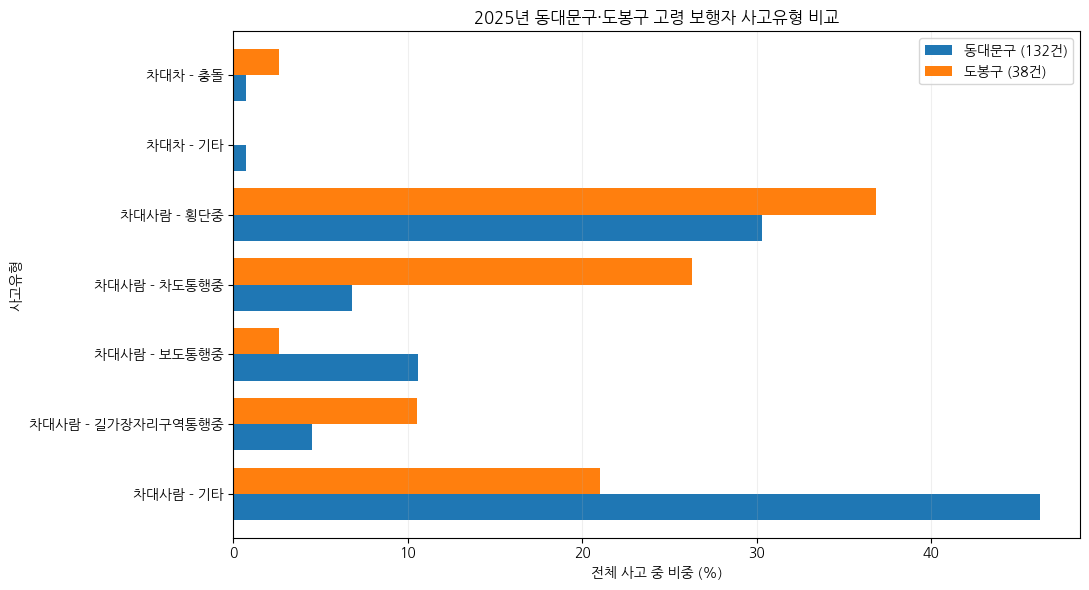

In [ ]:

# 사고유형별 비중을 가로 막대그래프로 비교
ax = type_compare[
    ['동대문구_비중', '도봉구_비중']
].plot(
    kind='barh',
    figsize=(11, 6),
    width=0.75
)

plt.xlabel('전체 사고 중 비중 (%)')
plt.ylabel('사고유형')
plt.title('2025년 동대문구·도봉구 고령 보행자 사고유형 비교')
plt.legend(['동대문구 (132건)', '도봉구 (38건)'])
plt.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()


In [ ]:

from google.colab import files
files.upload()  # 두 엑셀 파일 모두 선택

# 과거 사고 기록 불러오기
dobong_past = pd.read_excel(
    "2022-2024_도봉구_고령보행자사고상세.xlsx"
)

dongdaemun_past = pd.read_excel(
    "2022-2024_동대문구_고령보행자사고상세.xlsx"
)

# 기존 자료처럼 '발생년월'에 연도 정보가 있는지 확인
print("도봉구:", dobong_past.shape)
print("동대문구:", dongdaemun_past.shape)

display(dobong_past[['발생년월']].head())
display(dongdaemun_past[['발생년월']].head())


Saving 2022-2024_도봉구_고령보행자사고상세.xlsx to 2022-2024_도봉구_고령보행자사고상세.xlsx
Saving 2022-2024_동대문구_고령보행자사고상세.xlsx to 2022-2024_동대문구_고령보행자사고상세.xlsx
도봉구: (171, 22)
동대문구: (423, 22)


,발생년월
0,2022년 1월
1,2022년 1월
2,2022년 1월
3,2022년 1월
4,2022년 1월


,발생년월
0,2022년 1월
1,2022년 1월
2,2022년 1월
3,2022년 1월
4,2022년 1월


In [ ]:

# 과거 자료와 2025년 자료를 각각 합치기
dobong_all = pd.concat([dobong_past, dobong], ignore_index=True)
dongdaemun_all = pd.concat([dongdaemun_past, detail], ignore_index=True)

# 발생년월에서 연도만 추출
dobong_all['연도'] = dobong_all['발생년월'].str[:4].astype(int)
dongdaemun_all['연도'] = dongdaemun_all['발생년월'].str[:4].astype(int)

# 연도별 사고 건수 계산
year_compare = pd.DataFrame({
    '동대문구': dongdaemun_all['연도'].value_counts(),
    '도봉구': dobong_all['연도'].value_counts()
}).sort_index()

# 두 지역의 사고 건수 비율
year_compare['동대문구/도봉구'] = (
    year_compare['동대문구'] / year_compare['도봉구']
).round(2)

display(year_compare)


,동대문구,도봉구,동대문구/도봉구
연도,,,
2022,138,49,2.82
2023,155,61,2.54
2024,130,61,2.13
2025,132,38,3.47


In [ ]:

from google.colab import files
files.upload()  # 2022-2023-2024_고령인구.csv 선택

# 3줄짜리 머리글을 읽어 연도와 지표를 구분
population_years = pd.read_csv(
    '2022-2023-2024_고령인구.csv',
    header=[0, 1, 2],
    encoding='utf-8-sig'
)

# 65세 이상 고령자 인구 추출
elderly_population = pd.DataFrame({
    '동대문구': [
        population_years.loc[
            population_years.iloc[:, 1] == '동대문구',
            (f'{year} 4/4', '65세이상고령자 (명)', '소계')
        ].iloc[0]
        for year in [2022, 2023, 2024]
    ],
    '도봉구': [
        population_years.loc[
            population_years.iloc[:, 1] == '도봉구',
            (f'{year} 4/4', '65세이상고령자 (명)', '소계')
        ].iloc[0]
        for year in [2022, 2023, 2024]
    ]
}, index=[2022, 2023, 2024])

# 기존 2025년 인구 추가
elderly_population.loc[2025] = [72779, 78335]

# 연도별 고령인구 1만 명당 사고 건수
rate_compare = (
    year_compare[['동대문구', '도봉구']]
    / elderly_population
    * 10000
).round(2)

display(rate_compare)


Saving 2022-2023-2024_고령인구.csv to 2022-2023-2024_고령인구.csv


,동대문구,도봉구
연도,,
2022,21.41,7.31
2023,23.12,8.66
2024,18.68,8.22
2025,18.14,4.85


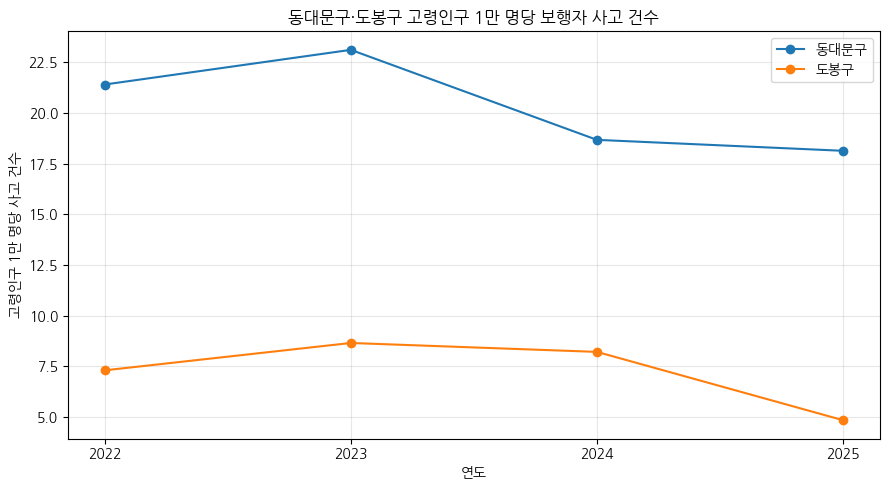

In [ ]:

ax = rate_compare.plot(
    kind='line',
    marker='o',
    figsize=(9, 5)
)

plt.title('동대문구·도봉구 고령인구 1만 명당 보행자 사고 건수')
plt.xlabel('연도')
plt.ylabel('고령인구 1만 명당 사고 건수')
plt.xticks([2022, 2023, 2024, 2025])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [2]:

import requests
from getpass import getpass

# 서비스키를 화면에 표시하지 않고 입력
service_key = getpass("서비스키 입력: ")

url = "https://www.safetydata.go.kr/V2/api/DSSP-IF-10002"

params = {
    "serviceKey": service_key,
    "pageNo": 1,
    "numOfRows": 5,
    "returnType": "json"
}

response = requests.get(url, params=params, timeout=30)

print("HTTP 상태 코드:", response.status_code)

# 응답이 JSON이면 구조만 확인
try:
    data = response.json()
    print("응답 최상위 항목:", list(data.keys()))
    for key, value in data.items():
        print(key, ":", type(value).__name__)
except ValueError:
    print("JSON 응답이 아닙니다.")
    print(response.text[:300])


# API가 제공하는 전체 데이터 건수
print("전체 데이터 건수:", data['totalCount'])

# 이번 요청으로 받은 데이터 건수
print("받은 데이터 건수:", len(data['body']))

# 실제 데이터의 열 이름 확인
print("데이터 열 이름:")
print(list(data['body'][0].keys()))

# 첫 번째 보호구역의 일부 정보 확인
import pandas as pd

sample = pd.DataFrame(data['body'])
display(sample.head())



서비스키 입력: ··········
HTTP 상태 코드: 200
응답 최상위 항목: ['header', 'numOfRows', 'pageNo', 'totalCount', 'body']
header : dict
numOfRows : int
pageNo : int
totalCount : int
body : list
전체 데이터 건수: 4453
받은 데이터 건수: 5
데이터 열 이름:
['DTIN_CRTR_YMD', 'SGG_CD', 'LCTN_LOTNO_ADDR', 'MNG_INST_TELNO', 'PRTC_ZONE_ROAD_WDTH_DTL', 'SGG_NM', 'CCTV_INSTLN_YN', 'CCTV_INSTLN_CNT', 'LCTN_ROAD_NM_ADDR', 'CTPV_NM', 'PRTC_ZONE_SEQ', 'LOT', 'LMT_SPD', 'MNG_INST_NM', 'DTIN_SE', 'OBFA_NM', 'FCLT_KND_CD', 'CMPTNC_POLSTN_NM', 'GEOM', 'LOCA_LMT_SPD', 'LAT']


,DTIN_CRTR_YMD,SGG_CD,LCTN_LOTNO_ADDR,MNG_INST_TELNO,PRTC_ZONE_ROAD_WDTH_DTL,SGG_NM,CCTV_INSTLN_YN,CCTV_INSTLN_CNT,LCTN_ROAD_NM_ADDR,CTPV_NM,...,LOT,LMT_SPD,MNG_INST_NM,DTIN_SE,OBFA_NM,FCLT_KND_CD,CMPTNC_POLSTN_NM,GEOM,LOCA_LMT_SPD,LAT
0,20190331,11230,서울특별시 동대문구 제기동 445 경동빌딩 제기동 445 경동빌딩,029622262,14,동대문구,2,0,서울특별시 동대문구 약령시로 122-5 (제기동) 제기동 445 경동빌딩,서울특별시,...,127.043777,30,서울특별시 동대문구,C0103,경동요양병원,2,서울지방경찰청 서울동대문,"POLYGON((127.04357725338284 37.58318474373362,...",30,37.583014
1,20190331,11230,서울특별시 동대문구 제기동 445 경동빌딩 제기동 445 경동빌딩,029622262,21,동대문구,1,1,서울특별시 동대문구 약령시로 122-5 (제기동) 제기동 445 경동빌딩,서울특별시,...,127.043777,30,서울특별시 동대문구,C0103,경동요양병원,2,서울지방경찰청 서울동대문,"POLYGON((127.04402183698508 37.58354722857662,...",30,37.583014
2,20190331,11230,서울특별시 동대문구 제기동 445 경동빌딩 제기동 445 경동빌딩,029622262,32,동대문구,2,0,서울특별시 동대문구 약령시로 122-5 (제기동) 제기동 445 경동빌딩,서울특별시,...,127.043777,50,서울특별시 동대문구,C0103,경동요양병원,2,서울지방경찰청 서울동대문,"POLYGON((127.04138284777844 37.57911797501422,...",50,37.583014
3,20190331,11230,서울특별시 동대문구 제기동 122-444 제기동122-444,021231234,6,동대문구,2,0,서울특별시 동대문구 고산자로56길 53 (제기동) 제기동122-444,서울특별시,...,127.038784,30,서울특별시 동대문구,C0103,행복마을경로당,2,서울지방경찰청 서울동대문,"POLYGON((127.03844354674771 37.5892727266098,1...",30,37.590115
4,20190331,11230,서울특별시 동대문구 답십리동 36-31 답십리동36-31,021231234,6,동대문구,2,0,서울특별시 동대문구 답십리로48길 54 (답십리동) 답십리동36-31,서울특별시,...,127.057726,30,서울특별시 동대문구,C0103,중산경로당,2,서울지방경찰청 서울동대문,"POLYGON((127.05780276865791 37.57136924560433,...",30,37.570385


In [3]:

import requests
import pandas as pd

url = "https://www.safetydata.go.kr/V2/api/DSSP-IF-10002"

# 한 페이지에 500건씩 요청
page_size = 500
all_rows = []

for page in range(1, 11):
    params = {
        "serviceKey": service_key,
        "pageNo": page,
        "numOfRows": page_size,
        "returnType": "json"
    }

    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    result = response.json()
    rows = result["body"]

    all_rows.extend(rows)
    print(f"{page}페이지: {len(rows)}건 수집")

    # 마지막 페이지에 도달하면 종료
    if len(rows) < page_size:
        break

# 전체 데이터를 표로 변환
zones_all = pd.DataFrame(all_rows)

print("전체 수집 행 수:", len(zones_all))
print("서울 데이터 행 수:",
      (zones_all["CTPV_NM"] == "서울특별시").sum())

# 데이터 기준일 확인
print("\n데이터 기준일별 행 수:")
display(zones_all["DTIN_CRTR_YMD"].value_counts())


1페이지: 500건 수집
2페이지: 500건 수집
3페이지: 500건 수집
4페이지: 500건 수집
5페이지: 500건 수집
6페이지: 500건 수집
7페이지: 500건 수집
8페이지: 500건 수집
9페이지: 453건 수집
전체 수집 행 수: 4453
서울 데이터 행 수: 280

데이터 기준일별 행 수:


,count
DTIN_CRTR_YMD,
20190331,1983
20201019,98
20241226,75
20201020,73
20221101,50
...,...
20210629,1
20210625,1
20221215,1


In [4]:

# 서울 데이터만 추출
seoul_zones = zones_all[
    zones_all['CTPV_NM'] == '서울특별시'
].copy()

print("서울 전체 행 수:", len(seoul_zones))
print("보호구역 식별번호 종류:", seoul_zones['PRTC_ZONE_SEQ'].nunique())
print("시설명 종류:", seoul_zones['OBFA_NM'].nunique())

print("\n서울 데이터 기준일 분포:")
display(
    seoul_zones['DTIN_CRTR_YMD']
    .value_counts()
    .head(15)
)

print("\n자치구별 데이터 행 수:")
display(
    seoul_zones['SGG_NM']
    .value_counts()
)


서울 전체 행 수: 280
보호구역 식별번호 종류: 280
시설명 종류: 181

서울 데이터 기준일 분포:


,count
DTIN_CRTR_YMD,
20190331,186
20210823,8
20240730,8
20210822,5
20210428,5
20220719,4
20211221,4
20210812,4
20210414,4



자치구별 데이터 행 수:


,count
SGG_NM,
관악구,35
송파구,29
강남구,23
강서구,22
동대문구,17
은평구,17
서초구,16
성동구,12
성북구,11


## 분석 5. 노인보호구역은 고령 보행자 사고가 집중된 곳을 보호하고 있는가?

### 1. 분석 배경과 질문

앞선 분석에서 2025년 동대문구의 고령 보행자 사고는 132건, 도봉구는 38건으로 나타났다. 두 지역의 고령인구 규모는 비슷했지만, 사고 발생 수준의 차이는 2022~2025년에도 반복됐다.

그러나 이러한 차이가 발생하는 원인을 기존 통계만으로 설명하기는 어렵다.

이에 사고 원인을 직접 추정하기보다, **고령 보행자를 보호하기 위한 노인보호구역이 실제 사고 집중지역과 공간적으로 일치하는지** 확인하고자 한다.

핵심 분석 질문은 다음과 같다.

**노인보호구역은 고령 보행자 사고가 많이 발생하는 곳에 지정되어 있는가?**

### 2. 사용 데이터

**① 행정안전부 재난안전데이터 공유플랫폼 — 교통안전정보(노인보호구역)**

- API를 통해 전국 4,453행, 서울 280행 확보
- 주요 항목: 시설명, 자치구, 주소, 위도·경도, 보호구역 경계(`GEOM`), 데이터 기준일
- 서울 280행은 181개의 서로 다른 시설명을 포함하며, 하나의 시설에 여러 보호구역 경계가 등록된 사례가 있음
- 데이터 기준일이 혼재되어 있으므로 2025년 전체 지정 현황과 동일하다고 단정할 수 없음

**② 한국도로교통공단 — 보행노인 교통사고 다발지역 데이터**

- 2012~2025년 전국 사고다발지역 CSV 확보
- 2025년 서울 사고다발지역 71곳, 동대문구 10곳 확인
- 주요 항목: 지점명, 사고 건수, 중심 위도·경도, 사고다발지역 폴리곤

### 3. 현재까지의 확인 결과

동대문구의 노인보호구역 데이터는 17행이며, 서로 다른 시설 8곳에 대응한다. 이 중 제기동 소재 시설은 경동요양병원과 행복마을경로당 2곳이다.

한편 2025년 동대문구의 고령 보행자 사고다발지역 10곳 중 5곳이 제기동에 있다.

노인보호구역의 경계 정보를 이용해 지도 시각화를 구현했으며, 사고다발지역 데이터에서도 중심 좌표와 폴리곤 정보를 확보했다.

### 4. 아직 확인하지 않은 사항

- 사고다발지역과 노인보호구역의 실제 공간적 겹침 여부
- 보호구역과 겹치는 사고다발지역의 수와 위치
- 사고 집중지역이 보호구역 밖에 분포하는 정도

위 항목은 두 자료의 공간 경계를 비교한 뒤 판단한다.

**분석상 유의점:** 사고다발지역과 보호구역이 겹치거나 겹치지 않는다는 사실만으로 정책의 효과나 사고 원인을 판단할 수는 없다.

In [5]:

# 서울 노인보호구역 데이터 저장
filename = "서울_노인보호구역_API.csv"

seoul_zones.to_csv(
    filename,
    index=False,
    encoding="utf-8-sig"
)

# 내 컴퓨터로 다운로드
from google.colab import files
files.download(filename)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

import pandas as pd
from google.colab import files

# 기존 사고다발지역 엑셀 파일 업로드
files.upload()

# 데이터 불러오기
hotspots = pd.read_excel(
    "2025_서울_고령보행자사고다발지역.xlsx"
)

# 열 이름 확인
print("열 이름:", hotspots.columns.tolist())

# 동대문구 사고다발지역 10곳 확인
display(
    hotspots[
        hotspots['시도'].str.contains('동대문구', na=False)
    ]
)


Saving 2025_서울_고령보행자사고다발지역.xlsx to 2025_서울_고령보행자사고다발지역.xlsx
열 이름: ['시도', '장소설명', '사고건수', '사상자수', '사망자수', '중상자수', '경상자수', '부상신고자수']


,시도,장소설명,사고건수,사상자수,사망자수,중상자수,경상자수,부상신고자수
7,서울 동대문구1,서울 동대문구 제기동(동서시장 부근),12,12,0,12,0,0
8,서울 동대문구2,서울 동대문구 제기동(청량리전통시장 부근),10,10,0,10,0,0
9,서울 동대문구3,서울 동대문구 제기동(경동시장교차로 부근),6,6,2,4,0,0
10,서울 동대문구4,서울 동대문구 제기동(경동시장광성상가 부근),6,6,0,6,0,0
11,서울 동대문구5,서울 동대문구 장안동(장한평역교차로 부근),5,5,2,3,0,0
12,서울 동대문구6,서울 동대문구 신설동(양가네분식 부근),5,5,1,4,0,0
13,서울 동대문구7,서울 동대문구 청량리동(떡전교사거리 부근),5,5,1,4,0,0
14,서울 동대문구8,서울 동대문구 전농동(새성수약국 부근),5,5,0,5,0,0
15,서울 동대문구9,서울 동대문구 제기동(홍파초교교차로 부근),5,5,0,5,0,0
16,서울 동대문구10,서울 동대문구 회기동(회기역앞교차로 부근),5,5,0,5,0,0


In [8]:

# 동대문구 노인보호구역 자료 추출
dongdaemun_zones = seoul_zones[
    seoul_zones['SGG_NM'] == '동대문구'
].copy()

# 시설명, 주소, 위치 정보 확인
display(
    dongdaemun_zones[
        ['OBFA_NM', 'LCTN_ROAD_NM_ADDR',
         'LAT', 'LOT', 'PRTC_ZONE_SEQ']
    ]
)


,OBFA_NM,LCTN_ROAD_NM_ADDR,LAT,LOT,PRTC_ZONE_SEQ
0,경동요양병원,서울특별시 동대문구 약령시로 122-5 (제기동) 제기동 445 경동빌딩,37.583014,127.043777,44843
1,경동요양병원,서울특별시 동대문구 약령시로 122-5 (제기동) 제기동 445 경동빌딩,37.583014,127.043777,44846
2,경동요양병원,서울특별시 동대문구 약령시로 122-5 (제기동) 제기동 445 경동빌딩,37.583014,127.043777,44853
3,행복마을경로당,서울특별시 동대문구 고산자로56길 53 (제기동) 제기동122-444,37.590115,127.038784,44861
4,중산경로당,서울특별시 동대문구 답십리로48길 54 (답십리동) 답십리동36-31,37.570385,127.057726,44872
5,중산경로당,서울특별시 동대문구 답십리로48길 54 (답십리동) 답십리동36-31,37.570385,127.057726,44874
6,중산경로당,서울특별시 동대문구 답십리로48길 54 (답십리동) 답십리동36-31,37.570385,127.057726,44875
7,중산경로당,서울특별시 동대문구 답십리로48길 54 (답십리동) 답십리동36-31,37.570385,127.057726,44876
8,중산경로당,서울특별시 동대문구 답십리로48길 54 (답십리동) 답십리동36-31,37.570385,127.057726,44877
9,중산경로당,서울특별시 동대문구 답십리로48길 54 (답십리동) 답십리동36-31,37.570385,127.057726,44878


In [12]:

import folium
from shapely import wkt

zone_map = folium.Map(
    location=[37.582, 127.050],
    zoom_start=13,
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri"
)

# 실제 보호구역 경계 표시
for _, row in dongdaemun_zones.iterrows():
    polygon = wkt.loads(row['GEOM'])

    folium.GeoJson(
        polygon.__geo_interface__,
        style_function=lambda feature: {
            'color': '#D62828',
            'weight': 5,
            'fillColor': '#D62828',
            'fillOpacity': 0.2
        },
        tooltip=f"{row['OBFA_NM']} / {row['LCTN_ROAD_NM_ADDR']}"
    ).add_to(zone_map)

# 같은 시설에 여러 경계가 있어도 마커는 한 번만 표시
facilities = dongdaemun_zones.drop_duplicates(
    subset=['OBFA_NM', 'LAT', 'LOT']
)

for _, row in facilities.iterrows():
    folium.CircleMarker(
        location=[row['LAT'], row['LOT']],
        radius=6,
        color='#D62828',
        fill=True,
        fill_opacity=1,
        tooltip=row['OBFA_NM']
    ).add_to(zone_map)

zone_map.fit_bounds([
    [dongdaemun_zones['LAT'].min() - 0.005,
     dongdaemun_zones['LOT'].min() - 0.005],
    [dongdaemun_zones['LAT'].max() + 0.005,
     dongdaemun_zones['LOT'].max() + 0.005]
])

display(zone_map)


In [13]:

import pandas as pd
from google.colab import files

# 새로 확보한 사고다발지역 공간정보 업로드
files.upload()

# CSV 읽기
accident_spots = pd.read_csv(
    "2012-2025_전국_고령보행자사고다발지역.csv",
    encoding="cp949",
    dtype={"사고다발지id": str}
)

# 기존 2025년 TAAS 자료에 해당하는 동대문구 10곳
dongdaemun_spots = accident_spots[
    (accident_spots["사고다발지id"] == "2026121") &
    (accident_spots["시도시군구명"].str.contains("동대문구"))
].copy()

print("동대문구 사고다발지역:", len(dongdaemun_spots))

display(
    dongdaemun_spots[
        ["지점명", "사고건수", "경도", "위도"]
    ]
)


Saving 2012-2025_전국_고령보행자사고다발지역.csv to 2012-2025_전국_고령보행자사고다발지역.csv
동대문구 사고다발지역: 10


,지점명,사고건수,경도,위도
5998,서울 동대문구 제기동(동서시장 부근),12,127.040992,37.579327
5999,서울 동대문구 제기동(청량리전통시장 부근),10,127.043179,37.579805
6000,서울 동대문구 제기동(경동시장교차로 부근),6,127.039033,37.578388
6001,서울 동대문구 제기동(경동시장광성상가 부근),6,127.038402,37.580283
6002,서울 동대문구 장안동(장한평역교차로 부근),5,127.065478,37.561567
6003,서울 동대문구 신설동(양가네분식 부근),5,127.023643,37.572695
6004,서울 동대문구 청량리동(떡전교사거리 부근),5,127.051738,37.585996
6005,서울 동대문구 전농동(새성수약국 부근),5,127.051771,37.581445
6006,서울 동대문구 제기동(홍파초교교차로 부근),5,127.037810,37.586470
6007,서울 동대문구 회기동(회기역앞교차로 부근),5,127.055450,37.589490


In [14]:
print(accident_spots.columns.tolist())

display(
    dongdaemun_spots[
        ['지점명', '사고건수', '다발지역폴리곤']
    ].head(3)
)

['사고다발지fid', '사고다발지id', '법정동코드', '지점코드', '시도시군구명', '지점명', '사고건수', '사상자수', '사망자수', '중상자수', '경상자수', '부상신고자수', '경도', '위도', '다발지역폴리곤']


,지점명,사고건수,다발지역폴리곤
5998,서울 동대문구 제기동(동서시장 부근),12,"{""type"":""Polygon"",""coordinates"":[[[127.0427887..."
5999,서울 동대문구 제기동(청량리전통시장 부근),10,"{""type"":""Polygon"",""coordinates"":[[[127.0449760..."
6000,서울 동대문구 제기동(경동시장교차로 부근),6,"{""type"":""Polygon"",""coordinates"":[[[127.0408300..."


In [15]:

import json
import pandas as pd
from shapely import wkt
from shapely.geometry import shape

# 노인보호구역 경계를 도형으로 변환
zone_shapes = [
    wkt.loads(geom)
    for geom in dongdaemun_zones['GEOM']
]

# 사고다발지역 경계를 도형으로 변환
spot_shapes = [
    shape(json.loads(geom))
    for geom in dongdaemun_spots['다발지역폴리곤']
]

# 사고다발지역별 보호구역 겹침 여부
overlap_results = []

for (_, spot), spot_shape in zip(
    dongdaemun_spots.iterrows(), spot_shapes
):
    overlapping_zones = [
        zone
        for zone in zone_shapes
        if spot_shape.intersects(zone)
    ]

    overlap_results.append({
        '사고다발지역': spot['지점명'],
        '사고건수': spot['사고건수'],
        '보호구역과_겹침': len(overlapping_zones) > 0
    })

overlap_df = pd.DataFrame(overlap_results)

display(overlap_df)

print(
    "노인보호구역과 겹치는 사고다발지역:",
    overlap_df['보호구역과_겹침'].sum(),
    "/",
    len(overlap_df)
)


,사고다발지역,사고건수,보호구역과_겹침
0,서울 동대문구 제기동(동서시장 부근),12,True
1,서울 동대문구 제기동(청량리전통시장 부근),10,True
2,서울 동대문구 제기동(경동시장교차로 부근),6,False
3,서울 동대문구 제기동(경동시장광성상가 부근),6,False
4,서울 동대문구 장안동(장한평역교차로 부근),5,False
5,서울 동대문구 신설동(양가네분식 부근),5,False
6,서울 동대문구 청량리동(떡전교사거리 부근),5,True
7,서울 동대문구 전농동(새성수약국 부근),5,False
8,서울 동대문구 제기동(홍파초교교차로 부근),5,False
9,서울 동대문구 회기동(회기역앞교차로 부근),5,False


노인보호구역과 겹치는 사고다발지역: 3 / 10


In [16]:

import folium

# 기존 노인보호구역 지도에 사고다발지역 추가
for (_, spot), polygon in zip(
    dongdaemun_spots.iterrows(), spot_shapes
):
    folium.GeoJson(
        polygon.__geo_interface__,
        style_function=lambda feature: {
            'color': '#2563EB',
            'weight': 3,
            'fillColor': '#2563EB',
            'fillOpacity': 0.25
        },
        tooltip=f"{spot['지점명']} ({spot['사고건수']}건)"
    ).add_to(zone_map)

display(zone_map)


### 5. 분석 결과 — 사고다발지역과 노인보호구역의 공간적 관계

2025년 동대문구 고령 보행자 사고다발지역 10곳의 폴리곤과 노인보호구역 API의 경계 데이터를 비교했다.

Python의 `shapely`를 활용해 두 공간 경계가 서로 겹치거나 접촉하는지(`intersects`) 확인했다.

**분석 결과, 10곳 중 3곳은 보호구역 경계와 겹치거나 접촉했고, 7곳은 겹치지 않았다.**

보호구역 경계와 겹치거나 접촉한 사고다발지역은 다음과 같다.

- 제기동 동서시장 부근: 12건
- 제기동 청량리전통시장 부근: 10건
- 청량리동 떡전교사거리 부근: 5건

반면 제기동 경동시장교차로, 경동시장광성상가, 홍파초교교차로 등은 보호구역 경계와 겹치지 않았다.

특히 제기동 시장 일대에서도 사고 집중지역과 보호구역의 공간적 관계가 서로 다르게 나타났다.

#### 해석과 한계

이번 분석은 보호구역 지정 위치와 고령 보행자 사고 집중지역 사이에 공간적 불일치가 존재한다는 점을 보여준다.

다만 다음 사항에 유의해야 한다.

- 사고다발지역 폴리곤과 보호구역이 겹친다고 해서 개별 사고가 보호구역 안에서 발생했다는 뜻은 아니다.
- `intersects()`는 경계가 단순 접촉하는 경우도 포함하므로 실제 겹치는 면적은 별도로 측정하지 않았다.
- 노인보호구역 API의 데이터 기준일이 서로 달라 2025년 당시의 지정 상태와 정확히 일치한다고 단정할 수 없다.
- 사고다발지역 선정 기준에 해당하지 않는 장소에서 발생한 사고는 이번 공간 비교의 대상이 아니다.
- 공간적 불일치만으로 보호구역 지정 정책의 효과나 적절성을 확정할 수 없다.

#### 후속 취재 질문

**고령 보행자 사고가 반복적으로 집중되는 지역이 기존 노인보호구역 지정 범위에 포함되지 않는다면, 해당 지역의 보행안전은 어떤 제도로 관리되고 있는가?**